## MACHINE LEARING

In [3]:

# 1. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay



from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

In [4]:

df = pd.read_csv(r"C:\Users\Ezhilarasi\OneDrive\Desktop\AI_ML_Project\NLP\FINAL PROJECT\Telco-Customer-Churn-dataset-cleaned.csv")

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (7043, 23)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,tenure-binned,MonthlyCharges-binned,TotalCharges-binned,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,...,No,Month-to-month,Yes,Electronic check,29.85,29.85,Low,Low,Low,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,...,No,One year,No,Mailed check,56.95,1889.50,Medium,Medium,Low,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,...,No,Month-to-month,Yes,Mailed check,53.85,108.15,Low,Medium,Low,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,...,No,One year,No,Bank transfer (automatic),42.30,1840.75,Medium,Low,Low,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,...,No,Month-to-month,Yes,Electronic check,70.70,151.65,Low,Medium,Low,1


In [5]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 23 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   gender                 7043 non-null   str    
 1   SeniorCitizen          7043 non-null   int64  
 2   Partner                7043 non-null   str    
 3   Dependents             7043 non-null   str    
 4   tenure                 7043 non-null   int64  
 5   PhoneService           7043 non-null   str    
 6   MultipleLines          7043 non-null   str    
 7   InternetService        7043 non-null   str    
 8   OnlineSecurity         7043 non-null   str    
 9   OnlineBackup           7043 non-null   str    
 10  DeviceProtection       7043 non-null   str    
 11  TechSupport            7043 non-null   str    
 12  StreamingTV            7043 non-null   str    
 13  StreamingMovies        7043 non-null   str    
 14  Contract               7043 non-null   str    
 15  PaperlessBillin

In [6]:

print(df.isnull().sum())

gender                   0
SeniorCitizen            0
Partner                  0
Dependents               0
tenure                   0
PhoneService             0
MultipleLines            0
InternetService          0
OnlineSecurity           0
OnlineBackup             0
DeviceProtection         0
TechSupport              0
StreamingTV              0
StreamingMovies          0
Contract                 0
PaperlessBilling         0
PaymentMethod            0
MonthlyCharges           0
TotalCharges             0
tenure-binned            0
MonthlyCharges-binned    0
TotalCharges-binned      0
Churn                    0
dtype: int64


In [7]:
df['TotalCharges']

0         29.85
1       1889.50
2        108.15
3       1840.75
4        151.65
         ...   
7038    1990.50
7039    7362.90
7040     346.45
7041     306.60
7042    6844.50
Name: TotalCharges, Length: 7043, dtype: float64

<Axes: >

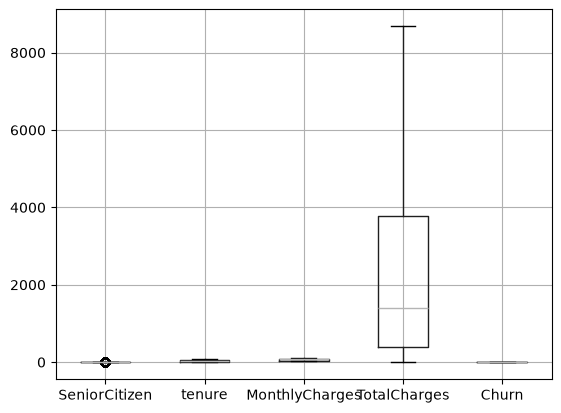

In [8]:
#outlaer check
df.boxplot()

In [9]:
# 2. Clean data
# TotalCharges may contain blank strings
if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(
        df["TotalCharges"], errors="coerce"
    )

In [10]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,tenure-binned,MonthlyCharges-binned,TotalCharges-binned,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,...,No,Month-to-month,Yes,Electronic check,29.85,29.85,Low,Low,Low,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,...,No,One year,No,Mailed check,56.95,1889.50,Medium,Medium,Low,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,...,No,Month-to-month,Yes,Mailed check,53.85,108.15,Low,Medium,Low,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,...,No,One year,No,Bank transfer (automatic),42.30,1840.75,Medium,Low,Low,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,...,No,Month-to-month,Yes,Electronic check,70.70,151.65,Low,Medium,Low,1


In [11]:
# 3. Separate input and target
X = df.drop(columns=["Churn"])
y = df["Churn"].astype(int)

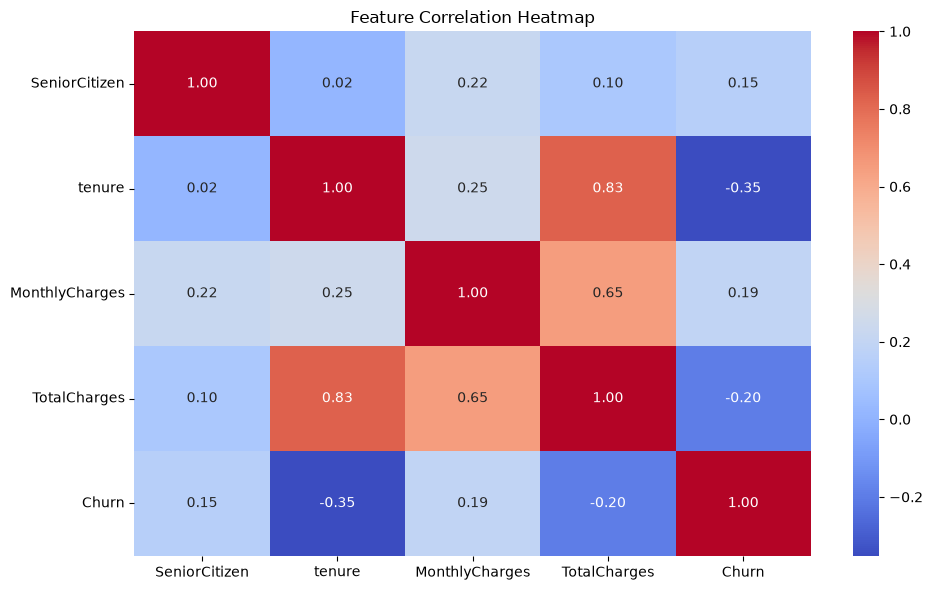

In [12]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

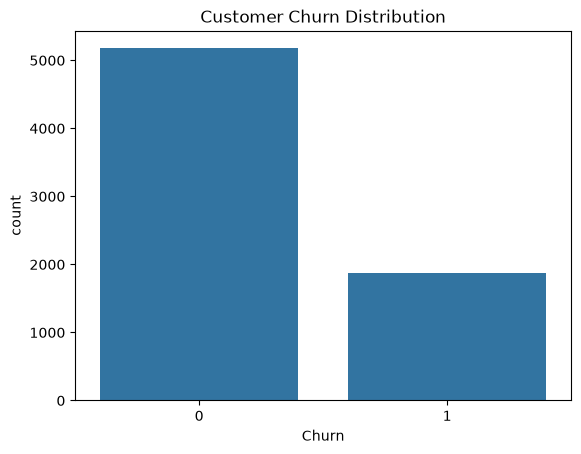

In [13]:
# 1. Churn Distribution
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.show()

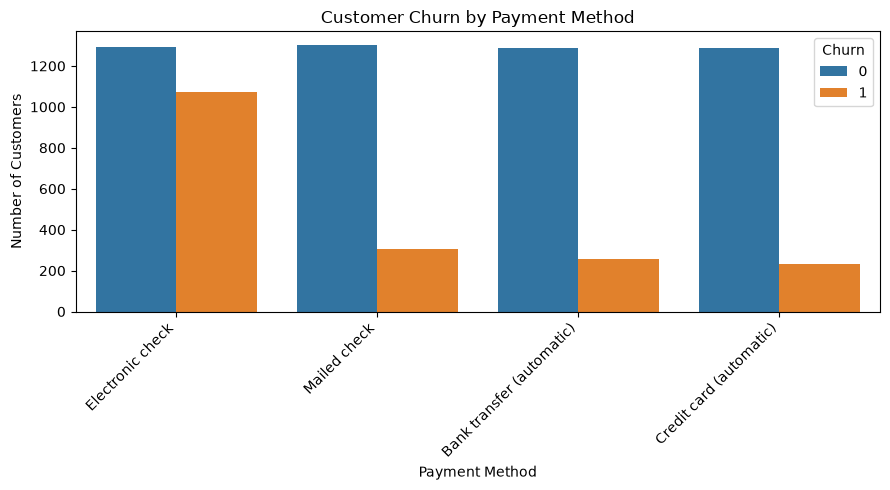

In [14]:
#Churn by Payment Method
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="PaymentMethod",
    hue="Churn"
)

plt.title("Customer Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

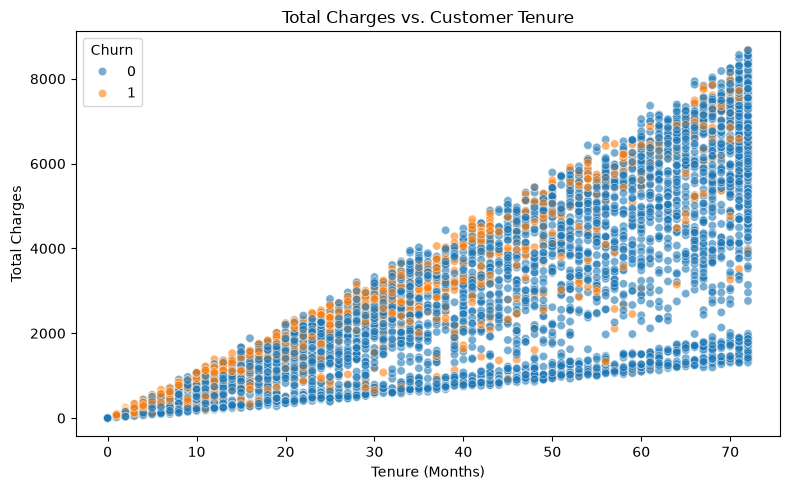

In [15]:
#Total Charges vs. Tenure

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="tenure",
    y="TotalCharges",
    hue="Churn",
    alpha=0.6
)

plt.title("Total Charges vs. Customer Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Total Charges")
plt.tight_layout()
plt.show()

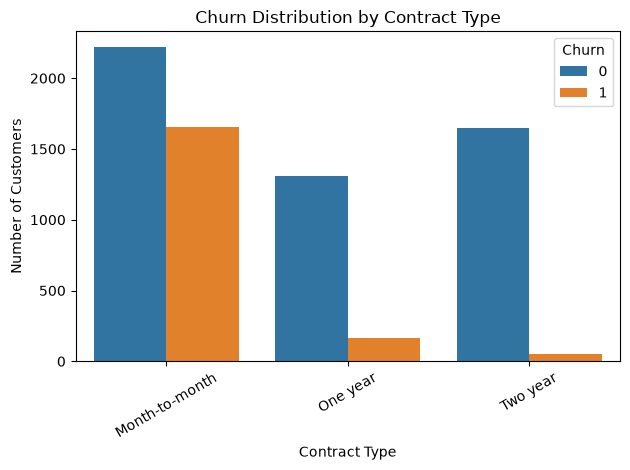

In [16]:
#1. Churn Distribution by Contract Type

import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=df, x="Contract", hue="Churn")

plt.title("Churn Distribution by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [17]:
# Identify categorical columns
categorical_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Identify numerical columns
numeric_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

# 6. CREATE CUSTOMER TEXT FOR TF-IDF
# Fill missing categorical values
X[categorical_cols] = X[categorical_cols].fillna("Unknown")

# Combine categorical columns into one text column
X["customer_text"] = X[categorical_cols].astype(str).agg(
    " ".join, axis=1
)

# Check whether the column exists
print(X[["customer_text"]].head())

C:\Users\Ezhilarasi\AppData\Local\Temp\ipykernel_13044\2355324949.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(


                                       customer_text
0  Female Yes No No No phone service DSL No Yes N...
1  Male No No Yes No DSL Yes No Yes No No No One ...
2  Male No No Yes No DSL Yes Yes No No No No Mont...
3  Male No No No No phone service DSL Yes No Yes ...
4  Female No No Yes No Fiber optic No No No No No...


In [18]:
# 5. TF-IDF
tfidf = TfidfVectorizer()
X_text = tfidf.fit_transform(X["customer_text"])


In [19]:
# 6. Split data
X_train, X_test, y_train, y_test = train_test_split(
    X_text, y, test_size=0.2,
    random_state=42, stratify=y
)

In [20]:
# 7. Models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": SVC()
}

In [21]:
# 8. Train and check accuracy
for name, model in models.items():
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)

    accuracy = accuracy_score(y_test, prediction)
    precision = precision_score(y_test, prediction, zero_division=0)
    recall = recall_score(y_test, prediction, zero_division=0)
    f1 = f1_score(y_test, prediction, zero_division=0)
    print("\nModel:", name)
    print("Accuracy :", round(accuracy * 100, 2), "%")
    print("Precision:", round(precision * 100, 2), "%")
    print("Recall   :", round(recall * 100, 2), "%")
    print("F1-Score :", round(f1 * 100, 2), "%")
    



Model: Logistic Regression
Accuracy : 77.15 %
Precision: 58.9 %
Recall   : 45.99 %
F1-Score : 51.65 %

Model: KNN
Accuracy : 75.73 %
Precision: 54.47 %
Recall   : 52.14 %
F1-Score : 53.28 %

Model: Random Forest
Accuracy : 75.8 %
Precision: 54.65 %
Recall   : 51.87 %
F1-Score : 53.22 %

Model: SVM
Accuracy : 77.64 %
Precision: 59.61 %
Recall   : 48.93 %
F1-Score : 53.74 %


Logistic Regression Accuracy: 77.15 %


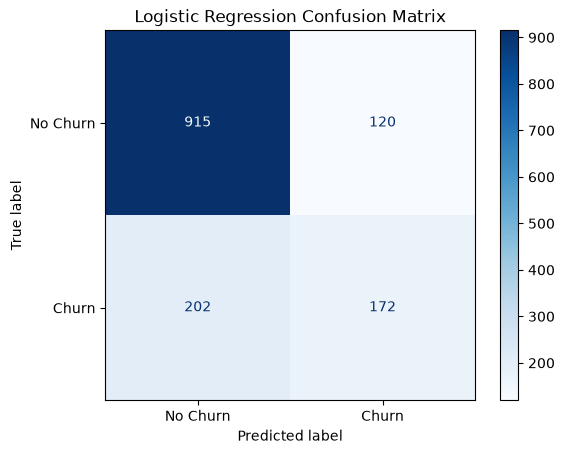

KNN Accuracy: 75.73 %


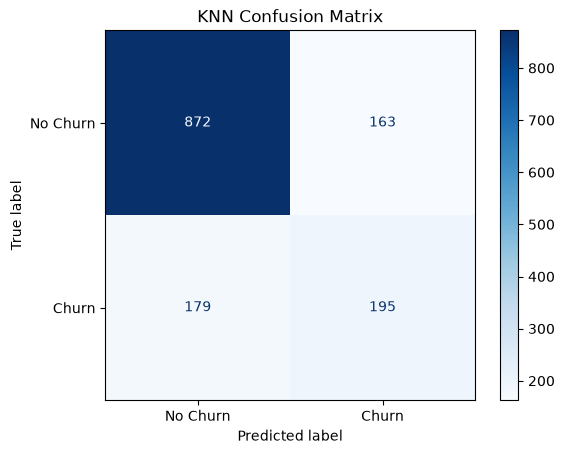

Random Forest Accuracy: 75.8 %


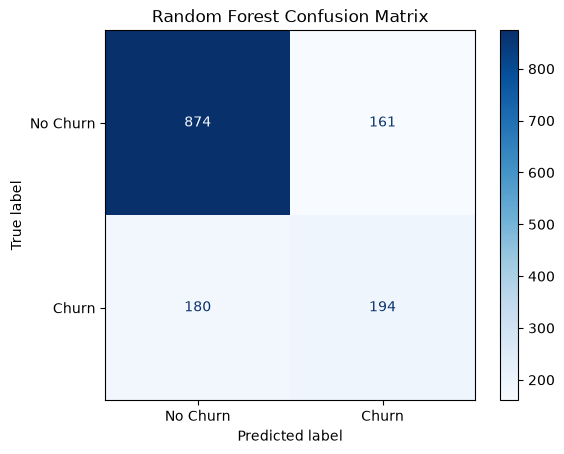

SVM Accuracy: 77.64 %


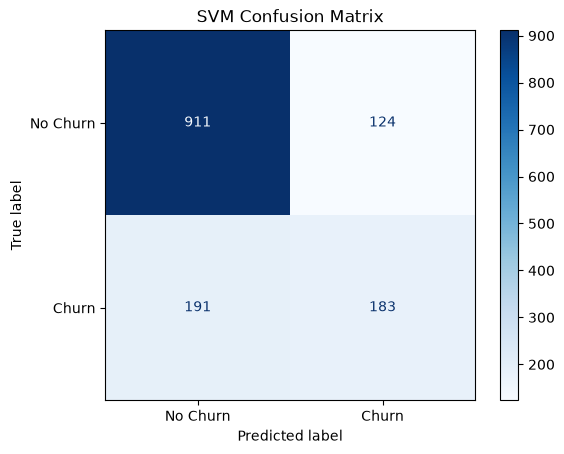

In [22]:
for name, model in models.items():
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)

    accuracy = accuracy_score(y_test, prediction)
    print(name, "Accuracy:", round(accuracy * 100, 2), "%")

    # Confusion matrix
    cm = confusion_matrix(y_test, prediction)

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Churn", "Churn"]
    )

    display.plot(cmap="Blues")
    plt.title(name + " Confusion Matrix")
    plt.show()

Logistic Regression ROC-AUC Score: 0.8149
KNN ROC-AUC Score: 0.7657
Random Forest ROC-AUC Score: 0.7787
SVM ROC-AUC Score: 0.7733


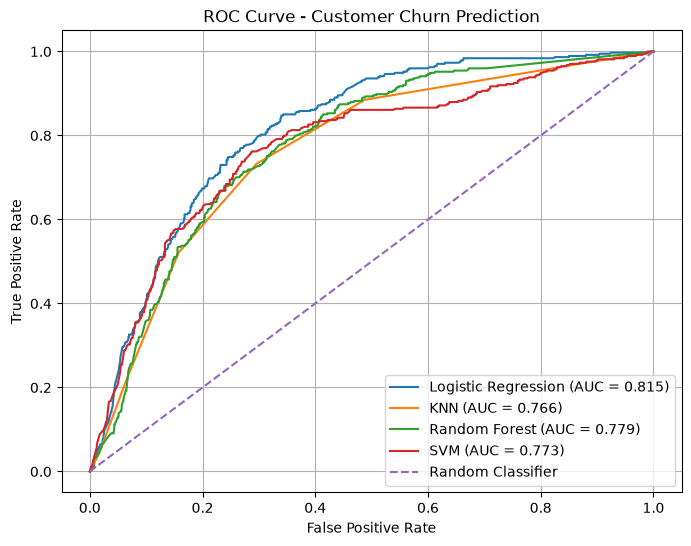

In [23]:
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

for name, model in models.items():
    # Train model
    model.fit(X_train, y_train)

    # Get prediction probabilities
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.decision_function(X_test)

    # Calculate ROC-AUC score
    roc_score = roc_auc_score(y_test, y_score)
    print(name, "ROC-AUC Score:", round(roc_score, 4))

    # Calculate ROC curve
    fpr, tpr, thresholds = roc_curve(y_test, y_score)

    # Plot ROC curve
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_score:.3f})")

# Random classifier reference line
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Customer Churn Prediction")
plt.legend()
plt.grid(True)
plt.show()

## DEEP LEARNING USING:RNN,LSTM

In [24]:

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, SimpleRNN, LSTM, Dense, Dropout, Bidirectional
)
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.21.0


In [25]:

da= pd.read_csv(r"C:\Users\Ezhilarasi\OneDrive\Desktop\AI_ML_Project\NLP\FINAL PROJECT\customer_churn_sentiment_dataset.csv")


In [26]:
da.head()

,CustomerID,Gender,Age,SubscriptionType,TenureMonths,MonthlyUsageHours,LastInteractionChannel,FeedbackText,SentimentLabel,Churn
0,C0001,Male,37,Premium,15,20,App,Very convenient and reliable service!,Positive,0
1,C0002,Female,52,Standard,12,33,Call,Service quality fluctuates sometimes.,Neutral,1
2,C0003,Female,25,Basic,22,9,Chat,"App works fine, nothing special to mention.",Neutral,0
3,C0004,Male,57,Standard,4,26,Email,"Fantastic experience, highly recommend!",Positive,0
4,C0005,Male,46,Premium,3,25,Email,"Smooth experience overall, everything works well.",Positive,0


In [27]:
print("Dataset shape:", da.shape)
print("Columns:", da.columns.tolist())


Dataset shape: (3000, 10)
Columns: ['CustomerID', 'Gender', 'Age', 'SubscriptionType', 'TenureMonths', 'MonthlyUsageHours', 'LastInteractionChannel', 'FeedbackText', 'SentimentLabel', 'Churn']


In [28]:
print("\nMissing values:")
print(da.isnull().sum())


Missing values:
CustomerID                0
Gender                    0
Age                       0
SubscriptionType          0
TenureMonths              0
MonthlyUsageHours         0
LastInteractionChannel    0
FeedbackText              0
SentimentLabel            0
Churn                     0
dtype: int64


In [29]:
#Clean and prepare the text

# Select the required columns
data = da[["FeedbackText", "SentimentLabel"]]
data.head()
data.shape

(3000, 2)

In [30]:
data['SentimentLabel'].unique()


<StringArray>
['Positive', 'Neutral', 'Negative']
Length: 3, dtype: str

In [31]:
# Display the shape of the DataFrame
print(f"Shape of the DataFrame: {data.shape}")

Shape of the DataFrame: (3000, 2)


In [32]:
# Display value counts for the 'SentimentLabel' column
print("Value counts for 'SentimentLabel' column:")
data['SentimentLabel'].value_counts()

Value counts for 'SentimentLabel' column:


SentimentLabel
Negative    1045
Positive    1007
Neutral      948
Name: count, dtype: int64

In [33]:
print("Number of null values per column:")
data.isnull().sum()

Number of null values per column:


FeedbackText      0
SentimentLabel    0
dtype: int64

In [34]:
import pickle
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
data['SentimentLabel'] = le.fit_transform(data['SentimentLabel'])
data

print(le.classes_)

for label, sentiment in enumerate(le.classes_):
    print(label, "=", sentiment)

['Negative' 'Neutral' 'Positive']
0 = Negative
1 = Neutral
2 = Positive


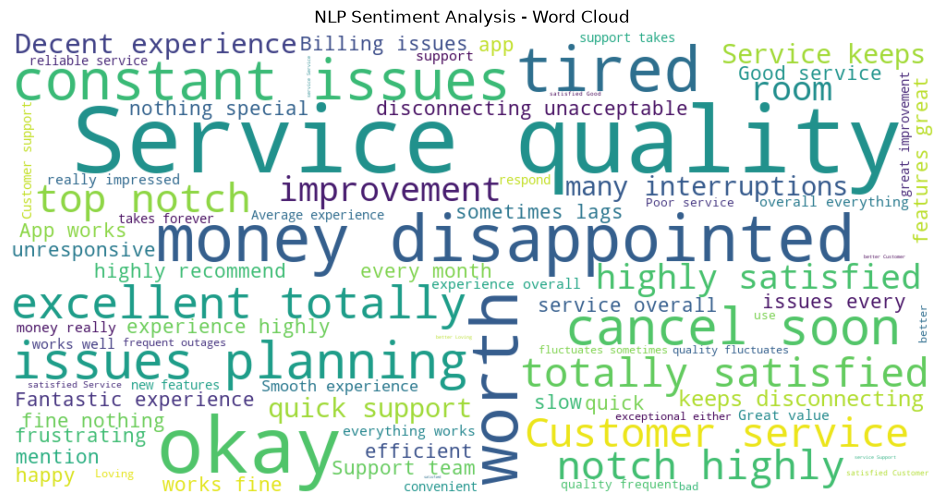

In [35]:

import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Combine all feedback text
text = " ".join(data["FeedbackText"].dropna().astype(str))

# Create word cloud
wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white",
    colormap="viridis"
).generate(text)

# Display diagram
plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("NLP Sentiment Analysis - Word Cloud")
plt.show()

# Save the diagram
wordcloud.to_file("sentiment_wordcloud.png")


Index(['FeedbackText', 'SentimentLabel'], dtype='str')


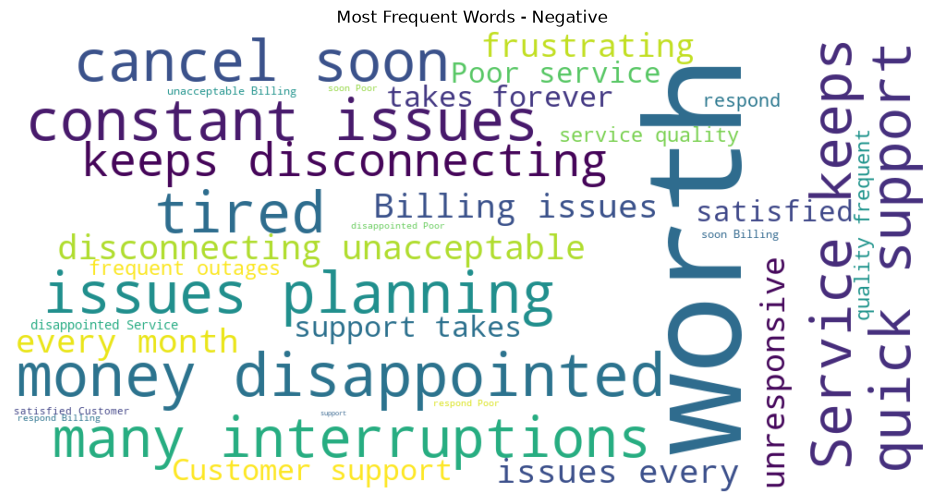

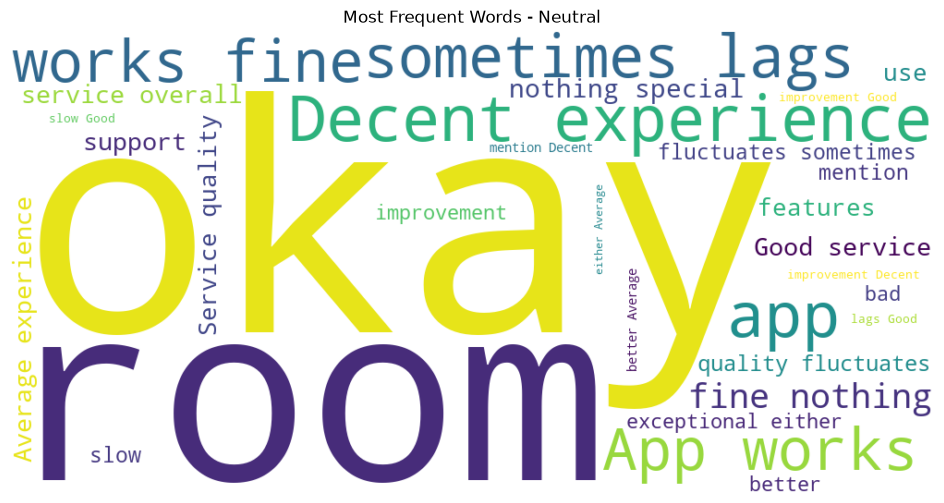

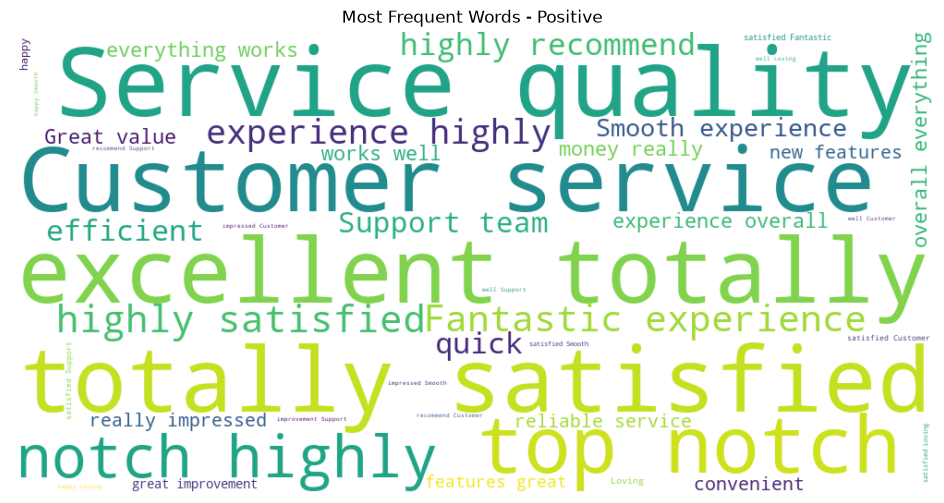

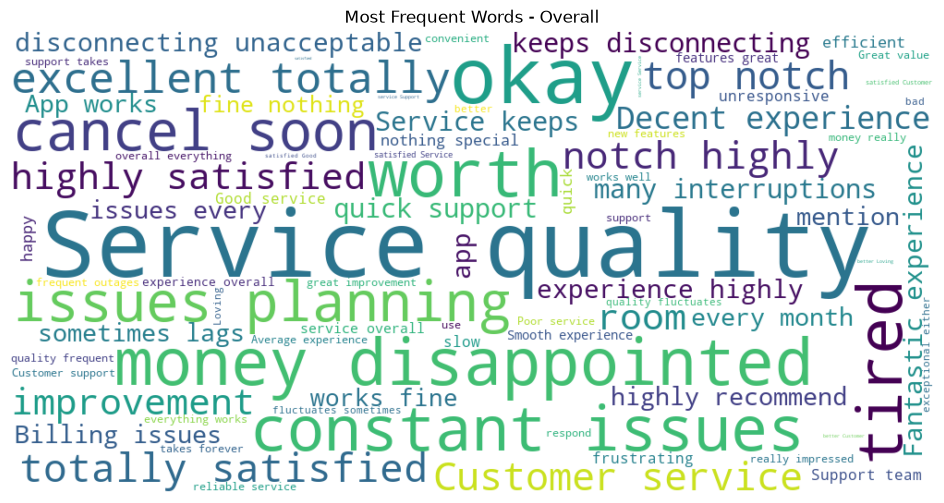

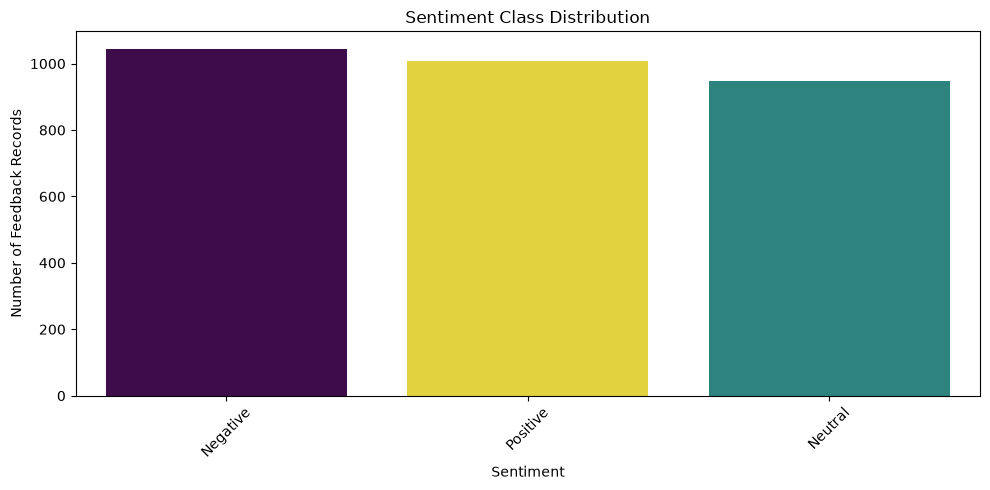

In [36]:

import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# Check your columns
print(data.columns)

# Create a cleaned text column if you have not already created one
data["cleaned"] = data["FeedbackText"].fillna("").astype(str)

# If SentimentLabel is encoded as 0, 1, 2,
# replace these names with the actual labels from your encoder.
label_names = le.classes_

# 1. Word Cloud for each sentiment class
for label_id, label_name in enumerate(label_names):

    all_text = " ".join(
        data.loc[data["SentimentLabel"] == label_id, "cleaned"]
    )

    if all_text.strip():
        wc = WordCloud(
            width=1000,
            height=500,
            background_color="white",
            max_words=150
        ).generate(all_text)

        plt.figure(figsize=(12, 6))
        plt.imshow(wc, interpolation="bilinear")
        plt.axis("off")
        plt.title(f"Most Frequent Words - {label_name}")
        plt.show()

# 2. Overall Word Cloud
all_text = " ".join(data["cleaned"])

if all_text.strip():
    wc = WordCloud(
        width=1000,
        height=500,
        background_color="white",
        max_words=150
    ).generate(all_text)

    plt.figure(figsize=(12, 6))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title("Most Frequent Words - Overall")
    plt.show()

# 3. Sentiment Class Distribution
plt.figure(figsize=(10, 5))

sns.countplot(
    data=data,
    x="SentimentLabel",
    order=data["SentimentLabel"].value_counts().index,
    hue="SentimentLabel",
    palette="viridis",
    legend=False
)

plt.title("Sentiment Class Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Feedback Records")
plt.xticks(
    ticks=range(len(label_names)),
    labels=[label_names[i] for i in
            data["SentimentLabel"].value_counts().index],
    rotation=45
)
plt.tight_layout()
plt.show()


Dataset shape after cleaning: (3000, 4)

Sentiment distribution:
SentimentLabel
0    1045
2    1007
1     948
Name: count, dtype: int64


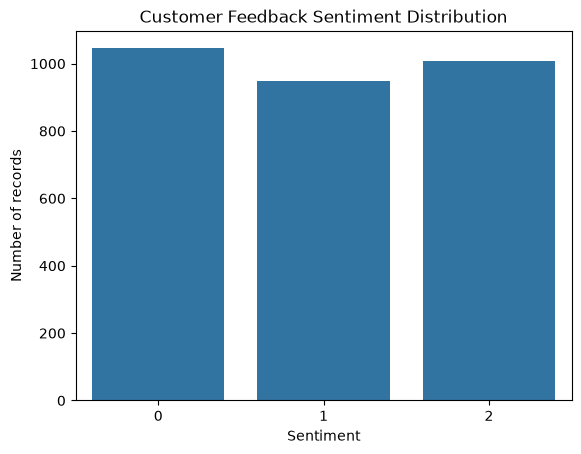

In [37]:
# Clean text
def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z0-9\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

data["CleanText"] = data["FeedbackText"].apply(clean_text)

print("Dataset shape after cleaning:", data.shape)
print("\nSentiment distribution:")
print(data["SentimentLabel"].value_counts())

sns.countplot(data=data, x="SentimentLabel")
plt.title("Customer Feedback Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of records")
plt.show()

In [38]:
data = data.copy()

data["CleanText"] = data["FeedbackText"].apply(clean_text)

In [39]:
X = data["CleanText"]
y = data["SentimentLabel"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 2400
Testing samples: 600


In [40]:
#Tokenization and padding
tokenizer = Tokenizer(num_words=5000, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

max_length = 100

X_train_pad = pad_sequences(
    X_train_seq, maxlen=max_length, padding="post", truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq, maxlen=max_length, padding="post", truncating="post"
)

vocab_size = min(5000, len(tokenizer.word_index) + 1)

print("Vocabulary size:", vocab_size)
print("Training shape:", X_train_pad.shape)

Vocabulary size: 95
Training shape: (2400, 100)


In [41]:
#Build and train the RNN model
rnn_model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=64),
    SimpleRNN(64),
    Dense(32, activation="relu"),
    Dense(3, activation="softmax")
])

rnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

rnn_model.summary()

rnn_history = rnn_model.fit(
    X_train_pad, y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.9505 - loss: 0.2665 - val_accuracy: 1.0000 - val_loss: 0.0136
Epoch 2/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 1.0000 - loss: 0.0061 - val_accuracy: 1.0000 - val_loss: 0.0034
Epoch 3/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 1.0000 - loss: 0.0023 - val_accuracy: 1.0000 - val_loss: 0.0017
Epoch 4/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 1.0000 - loss: 0.0013 - val_accuracy: 1.0000 - val_loss: 0.0011
Epoch 5/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 1.0000 - loss: 8.5129e-04 - val_accuracy: 1.0000 - val_loss: 7.2841e-04
Epoch 6/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 1.0000 - loss: 6.0117e-04 - val_accuracy: 1.0000 - val_loss: 5.3106e-04
Epoch 7/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 1.0000 - loss: 4.4853e-04 - val_accuracy: 1.0000 - val_loss: 4.0532e-04
Epoch 8/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 1.0000 - loss: 3.4820e-0

In [42]:
#Evaluate RNN
rnn_prob = rnn_model.predict(X_test_pad)
rnn_pred = np.argmax(rnn_prob, axis=1)

print("RNN Accuracy:", accuracy_score(y_test, rnn_pred))
print(classification_report(y_test, rnn_pred))

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step
RNN Accuracy: 1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       209
           1       1.00      1.00      1.00       190
           2       1.00      1.00      1.00       201

    accuracy                           1.00       600
   macro avg       1.00      1.00      1.00       600
weighted avg       1.00      1.00      1.00       600



In [43]:
#Build and train the LSTM model
lstm_model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=64),
    LSTM(64),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dense(3, activation="softmax")
])

lstm_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

lstm_model.summary()

lstm_history = lstm_model.fit(
    X_train_pad, y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - accuracy: 0.3484 - loss: 1.0986 - val_accuracy: 0.3000 - val_loss: 1.1092
Epoch 2/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.3531 - loss: 1.0987 - val_accuracy: 0.3000 - val_loss: 1.1041
Epoch 3/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.3604 - loss: 1.0981 - val_accuracy: 0.3000 - val_loss: 1.1050
Epoch 4/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.3568 - loss: 1.0972 - val_accuracy: 0.3000 - val_loss: 1.1064
Epoch 5/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.3521 - loss: 1.0983 - val_accuracy: 0.3000 - val_loss: 1.1042
Epoch 6/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.3604 - loss: 1.0974 - val_accuracy: 0.3000 - val_loss: 1.1052
Epoch 7/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.3573 - loss: 1.0976 - val_accuracy: 0.3000 - val_loss: 1.1020
Epoch 8/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.3609 - loss: 1.0978 - val_accuracy: 0.3000 - v

In [44]:
#Evaluate LSTM
lstm_prob = lstm_model.predict(X_test_pad)
lstm_pred = np.argmax(lstm_prob, axis=1)

print("LSTM Accuracy:", accuracy_score(y_test, lstm_pred))
print(classification_report(y_test, lstm_pred))

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step
LSTM Accuracy: 0.34833333333333333
              precision    recall  f1-score   support

           0       0.35      1.00      0.52       209
           1       0.00      0.00      0.00       190
           2       0.00      0.00      0.00       201

    accuracy                           0.35       600
   macro avg       0.12      0.33      0.17       600
weighted avg       0.12      0.35      0.18       600



c:\Users\Ezhilarasi\OneDrive\Desktop\AI_ML_Project\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Ezhilarasi\OneDrive\Desktop\AI_ML_Project\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Ezhilarasi\OneDrive\Desktop\AI_ML_Project\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(

In [45]:
#Compare RNN and LSTM
rnn_accuracy = accuracy_score(y_test, rnn_pred)
lstm_accuracy = accuracy_score(y_test, lstm_pred)

print("RNN Accuracy:", round(rnn_accuracy * 100, 2), "%")
print("LSTM Accuracy:", round(lstm_accuracy * 100, 2), "%")

if lstm_accuracy > rnn_accuracy:
    print("LSTM performed better on this test set.")
elif rnn_accuracy > lstm_accuracy:
    print("RNN performed better on this test set.")
else:
    print("Both models achieved the same accuracy.")

RNN Accuracy: 100.0 %
LSTM Accuracy: 34.83 %
RNN performed better on this test set.


In [46]:
import os, json, pickle

os.makedirs("artifacts", exist_ok=True)

pickle.dump(tfidf, open("artifacts/tfidf.pkl", "wb"))
pickle.dump(models, open("artifacts/ml_models.pkl", "wb"))

options = {c: sorted(df[c].dropna().astype(str).unique().tolist()) for c in categorical_cols}
json.dump(options, open("artifacts/categorical_options.json", "w"))

print("Saved in:", os.path.abspath("artifacts"))
print(os.listdir("artifacts"))

Saved in: c:\Users\Ezhilarasi\OneDrive\Desktop\AI_ML_Project\NLP\FINAL PROJECT\artifacts
['categorical_options.json', 'dl_metrics.json', 'label_encoder.pkl', 'lstm_model.keras', 'ml_models.pkl', 'rnn_model.keras', 'tfidf.pkl', 'tokenizer.pkl']


In [47]:
Embedding(input_dim=vocab_size, output_dim=64, mask_zero=True),

(<Embedding name=embedding_2, built=False>,)